In [ ]:
from google.colab import files
uploaded = files.upload()
filename = list(uploaded.keys())[0]
print(filename)

In [29]:
from scipy.ndimage import maximum_filter
import cv2
import numpy as np
import matplotlib.pyplot as plt

def detect_corners(image_path, method='shi-tomasi', alpha=0.04, window_size=5, threshold_ratio=0.01, nms_size=7):
    # 1.oku ve gri tonlamaya çevir
    img_color = cv2.imread(image_path)
    gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY).astype(np.float32)
    # 2.sobel gradyanları
    Ix = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    Iy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    Ixx, Iyy, Ixy = Ix*Ix, Iy*Iy, Ix*Iy
    # 3.pencerede topla (M matrisi bileşenleri)
    Sxx = cv2.boxFilter(Ixx, ddepth=-1, ksize=(window_size, window_size))
    Syy = cv2.boxFilter(Iyy, ddepth=-1, ksize=(window_size, window_size))
    Sxy = cv2.boxFilter(Ixy, ddepth=-1, ksize=(window_size, window_size))
    # 4.cornerness ölçütü (yönteme göre)
    if method == 'shi-tomasi':
        trace = Sxx + Syy
        det_term = np.sqrt(((Sxx - Syy) / 2) ** 2 + Sxy ** 2)
        response = trace / 2 - det_term   # λmin
    elif method == 'harris':
        det_H = Sxx * Syy - Sxy**2
        trace_H = Sxx + Syy
        response = det_H - alpha * (trace_H ** 2)
    else:
        raise ValueError("method 'shi-tomasi' ya da 'harris' olmalı")
    # 5.threshold + NMS
    threshold = threshold_ratio * response.max()
    mask = response > threshold
    local_max = maximum_filter(response, size=nms_size)
    is_local_max = (response == local_max)
    corners = mask & is_local_max

    return img_color, corners

In [30]:
def show_corners(img_color, corners, title='', save_path=None ):
    ys, xs = np.where(corners)
    plt.figure(figsize=(6,6))
    plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
    plt.scatter(xs, ys, s=15, c='red', marker='x')
    plt.title(f'{title} ({corners.sum()} köşe)')
    if save_path:
     plt.savefig(save_path, bbox_inches='tight')
    plt.show()

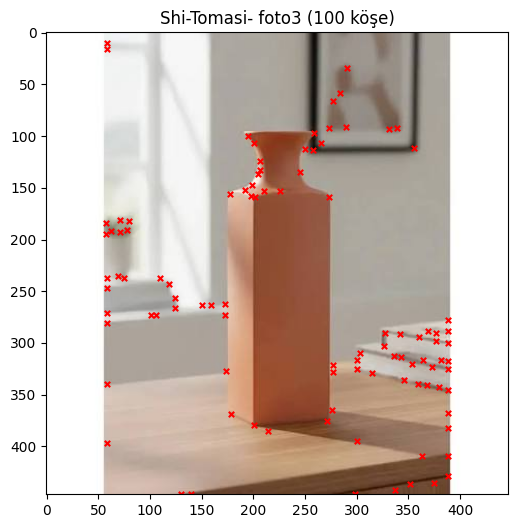

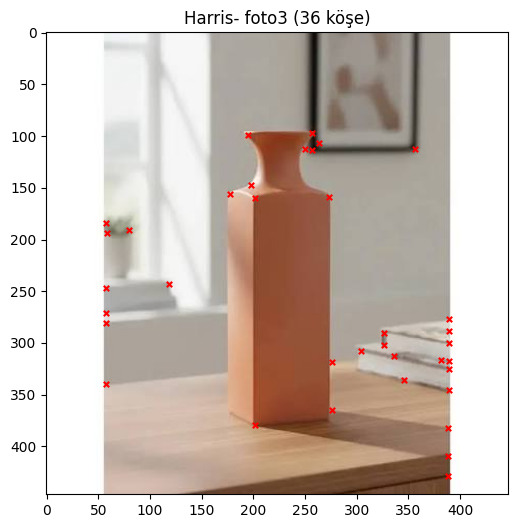

100
36


In [31]:
img, corners_st = detect_corners(filename, method='shi-tomasi')
show_corners(img, corners_st, title='Shi-Tomasi- foto3', save_path='shi_tomasi_foto3.png')

img, corners_h = detect_corners(filename, method='harris', alpha=0.04)
show_corners(img, corners_h, title='Harris- foto3', save_path='harris_foto3.png')
print(corners_st.sum())
print(corners_h.sum())